# Official mazes: navigation, keys and reward sparsity

MiniGrid Four Rooms randomizes the agent, goal and wall openings. Door Key requires object pickup and unlocking before reaching the goal. Our declared profile exposes the full symbolic map and pose; policies do not consume RGB pixels. Sparse and potential-shaped PPO use identical observations and budgets. A known-model BFS planner supplies a feasibility reference. Final scores always use the official reward.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

torch.set_num_threads(1)


def read(path):
    return json.loads((ROOT / path).read_text())

## All fitting seeds

Success rate is the fraction of 100 held-out layouts reaching the goal. Keep every fitted seed, rather than showing only the best animation.

In [2]:
rows = []
paths = [
    p
    for family in ["simulations", "geometry", "curriculum"]
    for p in (ROOT / "results/reference" / family).glob("MiniGrid*/*/metrics.json")
]
for path in sorted(paths):
    row = json.loads(path.read_text())
    rows.append(
        {
            k: row[k]
            for k in ["env", "profile", "seed", "success_fraction", "mean_length", "selected_step"]
        }
        | {"test_return": row["test"]["mean"]}
    )
frame = pd.DataFrame(rows)
assert len(frame) == 18
frame

,env,profile,seed,success_fraction,mean_length,selected_step,test_return
0,MiniGrid-FourRooms-v0,potential_curriculum,0,0.91,26.34,983040,0.753940
1,MiniGrid-FourRooms-v0,potential_curriculum,1,0.87,29.96,983040,0.717360
2,MiniGrid-FourRooms-v0,potential_curriculum,2,0.91,27.36,1048576,0.744760
3,MiniGrid-FourRooms-v0,potential_geometry,0,0.06,95.42,983040,0.047220
4,MiniGrid-FourRooms-v0,potential_geometry,1,0.03,97.14,1048576,0.028740
5,MiniGrid-FourRooms-v0,potential_geometry,2,0.43,68.76,1048576,0.324160
6,MiniGrid-DoorKey-6x6-v0,potential,0,0.97,22.72,720896,0.940200
7,MiniGrid-DoorKey-6x6-v0,potential,1,0.99,15.81,720896,0.959475
8,MiniGrid-DoorKey-6x6-v0,potential,2,0.96,28.85,458752,0.923875
9,MiniGrid-DoorKey-6x6-v0,sparse,0,1.00,18.18,458752,0.954550


## Potential differences telescope

Training adds F(s,s') = gamma Phi(s') - Phi(s). The goal terminal potential is zero. Time-limit truncations retain the next potential for value bootstrapping. The distance heuristic supplies map-derived training information; it never enters policy observations. Finite-horizon and discount assumptions matter when interpreting policy-invariance theory.

In [3]:
from decision_lab.navigation_planner import Planner
from decision_lab.simulation_envs import make_environment

env = make_environment("MiniGrid-DoorKey-6x6-v0", shaping=True)
obs, _ = env.reset(seed=300000)
planner = Planner(env)
phi0 = env.previous_potential
shaping_sum, official_return, t = 0.0, 0.0, 0
while True:
    action, _ = planner.predict(obs)
    obs, reward, terminated, truncated, info = env.step(action)
    shaping_sum += 0.99**t * info["shaping_reward"]
    official_return += info["official_reward"]
    t += 1
    if terminated or truncated:
        break
assert terminated and not truncated
assert np.isclose(shaping_sum, -phi0 + 0.99**t * env.previous_potential)
env.close()
print("Official return:", official_return, "discounted shaping sum:", shaping_sum)

Official return: 0.965 discounted shaping sum: 0.5500000000000002


## Portable actor deployment

Load numeric actor weights without an SB3 pickle, and replay the predetermined first three test layouts. Exact episode agreement is checked, including failure cases.

In [4]:
from decision_lab.simulation_deployment import load_actor
from decision_lab.simulations import evaluate

stem = "MiniGrid-DoorKey-6x6-v0_PPO_potential_0"
actor = load_actor(ROOT / "assets/actors" / (stem + ".npz"))
fresh = evaluate(actor, actor.metadata["case"], np.arange(3) + 300000)
evidence = np.load(ROOT / "assets/source_data/simulations" / (stem + ".npz"))
for key in ["returns", "lengths", "terminated", "truncated"]:
    np.testing.assert_array_equal(fresh[key], evidence[key][:3])
pd.DataFrame({k: fresh[k] for k in ["seeds", "returns", "lengths", "terminated", "truncated"]})

,seeds,returns,lengths,terminated,truncated
0,300000,0.0000,360,False,True
1,300001,0.9675,13,True,False
2,300002,0.9725,11,True,False


## Learning variability and model access

Each curve is one independently fitted policy; all validation rewards are unshaped. BFS receives the known transition model and is reported separately from sampled-interaction learning. View the fixed-episode GIFs in the repository gallery.

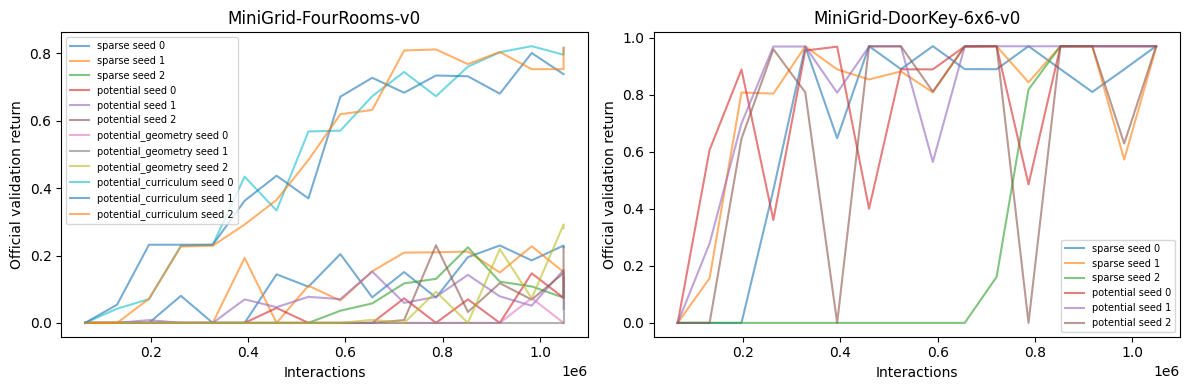

,env,method,success_fraction,mean_length
1,MiniGrid-FourRooms-v0,BFS,1.0,16.24
3,MiniGrid-DoorKey-6x6-v0,BFS,1.0,12.06


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, task in zip(axes, frame.env.unique()):
    for profile in ["sparse", "potential", "potential_geometry", "potential_curriculum"]:
        if (
            profile in ["potential_geometry", "potential_curriculum"]
            and task != "MiniGrid-FourRooms-v0"
        ):
            continue
        for seed in range(3):
            family = {"potential_geometry": "geometry", "potential_curriculum": "curriculum"}.get(
                profile, "simulations"
            )
            h = read(
                f"results/reference/{family}/{task}_PPO_{profile}/{seed}/validation_history.json"
            )
            ax.plot(
                [r["step"] for r in h],
                [r["mean_return"] for r in h],
                alpha=0.6,
                label=f"{profile} seed {seed}",
            )
    ax.set(title=task, xlabel="Interactions", ylabel="Official validation return")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
pd.DataFrame(read("docs/simulation_baselines.json")["rows"]).query("method == 'BFS'")[
    ["env", "method", "success_fraction", "mean_length"]
]